# Heart Disease Prediction System

## Setup: Running This Notebook From Scratch

Follow these steps in a terminal, inside this project's folder, before opening the notebook.

### 1. Check Python is installed
```
python --version
```
Any Python 3.9-3.12 should work.

### 2. Create a virtual environment
**Windows:** `python -m venv venv`  |  **macOS / Linux:** `python3 -m venv venv`

### 3. Activate the virtual environment
- **Windows (Command Prompt):** `venv\Scripts\activate.bat`
- **Windows (PowerShell):** `venv\Scripts\Activate.ps1`
- **macOS / Linux:** `source venv/bin/activate`

### 4. Install the required packages
```
pip install -r requirements.txt
```

### 5. Launch Jupyter Notebook
```
jupyter notebook
```
Open this `.ipynb` file and run all cells from the top (**Kernel -> Restart & Run All**).

---

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (1) or does not have heart disease (0) from a small set of clinical attributes.
##### **Application** It is used for learning data science and for seeing how clinical measurements relate to heart disease. **It is an educational project only - it is NOT a medical diagnosis tool.**

## Input and Output

### Inputs (Features / Attributes) - only 4 selected from the 13 available

| **Input Feature/Attribute** | **Meaning** | **Possible Values** |
| --- | --- | --- |
| **Sex** | Sex of the patient | 1 = Male, 0 = Female |
| **CP** | Chest pain type | 1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic |
| **Exang** | Exercise-induced angina | 1 = Yes, 0 = No |
| **Oldpeak** | ST depression induced by exercise relative to rest | Decimal number, 0.0 to about 6.2 |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **HeartDisease** | 1 = Yes (heart disease present), 0 = No (heart disease absent) |

## Developer & System Information

| | |
| --- | --- |
| **Developer Name** | Aleeha Mushtaq |
| **Program Name** | heart_disease_project |
| **IDE** | Jupyter Notebook |
| **Programming Language** | Python 3.12 |
| **Libraries** | NumPy 2.2.6, Pandas 2.3.3, Pickle (built-in), scikit-learn 1.7.2, PrettyTable, Matplotlib, Seaborn |
| **Dataset** | Heart Disease (UCI Machine Learning Repository) - Cleveland Clinic database, 303 patients |
| **Date of Completion** | 04/10/2026 |

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding - **Not required for this dataset**
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Feature Vector Check (no encoding needed)
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
- Step 9: Execute the Feedback Phase
- Step 10: Deploy Your Model as a Public Web App

## Code - Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, splitting
datasets, training a Support Vector Machine (SVM) model, evaluating accuracy,
and displaying results in tabular form.
"""

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
This part of the code loads the Cleveland Heart Disease dataset into a
pandas DataFrame. The file has NO header row, so we supply the 14 column
names ourselves (taken from the dataset documentation, heart-disease.names).
In this file a missing value is written as "?", so na_values="?" turns
those into NaN.
"""

# The 14 attributes of the processed Cleveland file (13 inputs + 1 output called "num")
all_columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
               "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# Read the data file and load it into a pandas DataFrame
raw_data = pd.read_csv("processed.cleveland.data", header=None,
                       names=all_columns, na_values="?")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data (first 10 rows):")
print("============================\n")

# Configure pandas to display all columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the first 10 rows of the dataset
print(raw_data.head(10))



Sample Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
3. Checking for missing values and looking at the original output ("num").
"""

# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(raw_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Sample Data:", raw_data["sex"].count())
print("========================================\n")

# Missing values per attribute
print("Missing values per attribute (only showing attributes with missing values):")
missing = raw_data.isna().sum()
print(missing[missing > 0])

# Original output attribute "num": 0 = no disease, 1-4 = disease (different severity levels)
print("\nOriginal output attribute 'num' - value counts:")
print(raw_data["num"].value_counts().sort_index())



Attributes in Sample Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')


Number of Instances in Sample Data: 303

Missing values per attribute (only showing attributes with missing values):
ca      4
thal    2
dtype: int64

Original output attribute 'num' - value counts:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
The Titanic data was already pre-processed. Here we need to do one pre-processing step:

| Problem | Fix |
| --- | --- |
| The output `num` has 5 values (0, 1, 2, 3, 4). We want a simple Yes/No answer. | Convert it to a binary label: `0` stays `0` (no disease), and `1, 2, 3, 4` all become `1` (disease present). |
| Missing values ("?") exist only in `ca` and `thal`. | **Nothing to do** - we do not use `ca` or `thal`, and our 4 selected attributes have no missing values. |

In [4]:
"""
Purpose of this section:
-------------------------
Convert the 5-level output "num" (0-4) into a binary output:
    0       -> 0 (heart disease absent)
    1,2,3,4 -> 1 (heart disease present)
"""

pre_processed_data = raw_data.copy()
pre_processed_data["HeartDisease"] = (raw_data["num"] > 0).astype(int)

print("Binary output attribute 'HeartDisease' - value counts:")
print(pre_processed_data["HeartDisease"].value_counts().sort_index())

Binary output attribute 'HeartDisease' - value counts:
HeartDisease
0    164
1    139
Name: count, dtype: int64


### Step 4: Feature Extraction
We select only **4 input attributes** from the 13 available (assignment constraint). The 4 were chosen because:

| Selected Attribute | Why it was selected |
| --- | --- |
| **Sex** | Heart disease rates differ clearly between males and females in this data. |
| **CP** (chest pain type) | Chest pain type is one of the strongest clinical indicators of heart disease. |
| **Exang** (exercise-induced angina) | Chest pain during exercise is a classic warning sign. |
| **Oldpeak** (ST depression) | ECG change under exercise stress, a standard heart-health measurement. |

All 4 are **already numeric**, have **no missing values**, and are on small, similar scales - so the data can go straight to the SVC with **no label encoding**.

In [5]:
"""
Purpose of this section:
-------------------------
Keep only the 4 selected input attributes and the output attribute.
The output attribute is placed LAST (the same layout as the Titanic data),
because later we split inputs and output using iloc[:, :-1] and iloc[:, -1].
"""

sample_data = pd.DataFrame({
    "Sex":          pre_processed_data["sex"].astype(int),
    "CP":           pre_processed_data["cp"].astype(int),
    "Exang":        pre_processed_data["exang"].astype(int),
    "Oldpeak":      pre_processed_data["oldpeak"],
    "HeartDisease": pre_processed_data["HeartDisease"],
})

# Save the extracted data (this plays the same role as sample-data.csv in the Titanic project)
sample_data.to_csv(r"sample-data.csv", index=False, header=True)

print("Sample Data after Feature Extraction:")
print("=====================================\n")
print(sample_data.head(10))
print("\nShape:", sample_data.shape)
print("\nData types:")
print(sample_data.dtypes)

Sample Data after Feature Extraction:

   Sex  CP  Exang  Oldpeak  HeartDisease
0    1   1      0      2.3             0
1    1   4      1      1.5             1
2    1   4      1      2.6             1
3    1   3      0      3.5             0
4    0   2      0      1.4             0
5    1   2      0      0.8             0
6    0   4      0      3.6             1
7    0   4      1      0.6             0
8    1   4      0      1.4             1
9    1   4      1      3.1             1

Shape: (303, 5)

Data types:
Sex               int64
CP                int64
Exang             int64
Oldpeak         float64
HeartDisease      int64
dtype: object


### Step 5: Label Encoding - Not Required
In the Titanic project, the inputs were **text** (`First`, `Male`, `Southampton`, ...), so they had to be converted to numbers with `LabelEncoder`.

In the Heart Disease data, **every attribute is already a number** (e.g. `Sex` is 1/0, `CP` is 1-4, `Oldpeak` is a decimal) and the output is already 0/1 after Step 3.2. So:

- Step 5.1 (train the label encoder) - **skipped**
- Step 5.2 (encode the output) - **skipped**
- Step 5.3 (encode the input) - **skipped**

`sample_data` goes directly to the training phase.

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [6]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.
"""

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=False keeps the original order of rows (no shuffling before splitting)
training_data, testing_data = train_test_split(
    sample_data,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

# Save the training and testing datasets to CSV files
training_data.to_csv(r"training-data.csv", index=False, header=True)
testing_data.to_csv(r"testing-data.csv", index=False, header=True)

print("Training Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [7]:
"""
Purpose of this section:
-------------------------
Separate the features (input vectors) and the labels (output values)
from the training dataset.
"""

# Extract input vectors (features) from training data
input_vector_train = training_data.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### Step 6.3: Train the Support Vector Classifier

In [8]:
"""
Purpose of this section:
-------------------------
Train a Support Vector Classifier (SVC) on the training data.
The SVC finds the best boundary to separate the two classes
(heart disease present vs. absent).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_model = svm.SVC(gamma='auto', random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [9]:
"""
Purpose of this section:
-------------------------
Save the trained Support Vector Classifier (SVC) model so it can be reused
later (and by the web app) without retraining.
"""

pickle.dump(svc_model, open('svc_trained_model.pkl', 'wb'))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [10]:
input_vector_test = testing_data.iloc[:, :-1]
output_label_test = testing_data.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [11]:
model = pickle.load(open('svc_trained_model.pkl', 'rb'))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [12]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data["Predictions"] = model_predictions
testing_data.to_csv(r"model-predictions.csv", index=False, header=True)

model_predictions = testing_data
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)



Predictions Returned by svc_trained_model:

     Sex  CP  Exang  Oldpeak  HeartDisease  Predictions
242    0   4      0      0.0             0            0
243    1   1      0      2.6             1            0
244    0   3      0      0.0             0            0
245    1   4      0      1.0             1            1
246    1   4      0      0.1             1            0
247    1   4      1      1.0             1            1
248    1   4      0      1.0             1            1
249    1   2      0      0.0             0            0
250    1   4      1      1.5             0            1
251    1   4      0      2.0             1            1
252    1   4      1      0.2             0            1
253    0   3      0      0.6             0            0
254    1   4      0      1.2             0            1
255    0   3      0      0.0             0            0
256    0   4      0      0.3             0            0
257    0   3      0      1.1             0            0
25

#### Step 7.4: Calculate the Accuracy Score

In [13]:
model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.72


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.67      0.83      0.74        29
   Heart Disease (1)       0.80      0.62      0.70        32

            accuracy                           0.72        61
           macro avg       0.73      0.73      0.72        61
        weighted avg       0.74      0.72      0.72        61


Confusion Matrix:

                          Predicted: No Heart Disease  \
Actual: No Heart Disease                           24   
Actual: Heart Disease                              12   

                          Predicted: Heart Disease  
Actual: No Heart Disease                         5  
Actual: Heart Disease                           20  


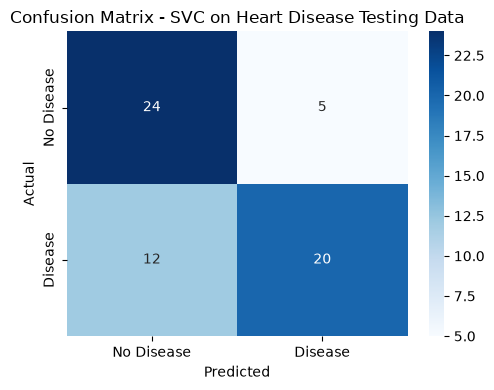

In [14]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading. This section adds the standard metrics:
- Precision: of everyone predicted "Heart Disease", how many really had it?
- Recall: of everyone who really had heart disease, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Heart Disease", "Actual: Heart Disease"],
    columns=["Predicted: No Heart Disease", "Predicted: Heart Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Heart Disease Testing Data')
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [15]:
"""
Purpose of this section:
-------------------------
Let the user enter their own data (Sex, CP, Exang, Oldpeak).
For this notebook copy we pre-fill a demo patient so the notebook can be
run top-to-bottom without typing anything.

To try your own values interactively, replace the four lines below with:
    sex_input     = int(input("Sex (1 = Male, 0 = Female): "))
    cp_input      = int(input("Chest pain type (1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic): "))
    exang_input   = int(input("Exercise induced angina (1 = Yes, 0 = No): "))
    oldpeak_input = float(input("ST depression (Oldpeak, e.g. 1.5): "))
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
sex_input = 1
cp_input = 4
exang_input = 1
oldpeak_input = 2.5

print(f"Sex: {sex_input}, CP: {cp_input}, Exang: {exang_input}, Oldpeak: {oldpeak_input}")

Sex: 1, CP: 4, Exang: 1, Oldpeak: 2.5


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [16]:
"""
Purpose of this section:
-------------------------
Convert the user's input into a structured feature vector (DataFrame).
The column names and column ORDER must be exactly the same as in the
training data: Sex, CP, Exang, Oldpeak.
"""

user_input = pd.DataFrame({
    'Sex': [sex_input],
    'CP': [cp_input],
    'Exang': [exang_input],
    'Oldpeak': [oldpeak_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

   Sex  CP  Exang  Oldpeak
0    1   4      1      2.5


#### Step 8.3: Feature Vector Check (no encoding needed)
In the Titanic project this step label-encoded the user's text input. Here the user's input is **already numeric**, so the feature vector from Step 8.2 can be given to the model as it is.

In [17]:
unseen_data_features = user_input.copy()

print("\n\nFeature Vector given to the model (already numeric):")
print("====================================================\n")
print(unseen_data_features)



Feature Vector given to the model (already numeric):

   Sex  CP  Exang  Oldpeak
0    1   4      1      2.5


#### Step 8.4: Load the Saved Model

In [18]:
model = pickle.load(open('svc_trained_model.pkl', 'rb'))

#### Step 8.5: Model Prediction

##### Step 8.5.1: Apply Model on the Feature Vector of the unseen instance and return Prediction to the User

In [19]:
predicted_disease = model.predict(unseen_data_features)

if predicted_disease == 1:
    prediction = "HEART DISEASE LIKELY"
if predicted_disease == 0:
    prediction = "HEART DISEASE NOT LIKELY"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [20]:
"""
Purpose of this section:
-------------------------
Step 9.1: The model's behaviour on a few example patients, together with
example feedback a domain expert / tester might give. (The feedback text is
an ILLUSTRATIVE example for this assignment - it is not from a real doctor.)
"""

cases = pd.DataFrame({
    "Sex":     [1, 0, 0],
    "CP":      [4, 2, 3],
    "Exang":   [1, 0, 0],
    "Oldpeak": [2.5, 0.0, 0.5],
})
cases["Model Prediction"] = model.predict(cases)

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Student Tester", "Student Tester"],
    "Case": [
        "Male, asymptomatic chest pain, exercise angina, ST depression 2.5",
        "Female, atypical angina, no exercise angina, ST depression 0.0",
        "Female, non-anginal pain, no exercise angina, ST depression 0.5",
    ],
    "Model Prediction": cases["Model Prediction"].map({1: "Heart disease", 0: "No heart disease"}),
    "Feedback": [
        "Plausible - exercise angina with a high ST depression is a known warning pattern.",
        "Plausible - low-risk profile on all four inputs.",
        "Reasonable, but 4 inputs are not enough for a real decision - important measurements are missing.",
    ],
})
print(example_feedback.to_string(index=False))

                  Reviewer                                                              Case Model Prediction                                                                                          Feedback
Domain Expert (Cardiology) Male, asymptomatic chest pain, exercise angina, ST depression 2.5    Heart disease                 Plausible - exercise angina with a high ST depression is a known warning pattern.
            Student Tester    Female, atypical angina, no exercise angina, ST depression 0.0 No heart disease                                                  Plausible - low-risk profile on all four inputs.
            Student Tester   Female, non-anginal pain, no exercise angina, ST depression 0.5 No heart disease Reasonable, but 4 inputs are not enough for a real decision - important measurements are missing.


#### Step 9.2: Make a List of Potential Improvements

In [21]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the test results and feedback.
"""

improvements = [
    "Recall for 'Heart Disease' is lower than precision (see Step 7.5): the model misses some real patients. In medicine a missed patient is costly, so the model should be tuned to improve recall.",
    "Use more than 4 inputs - e.g. max heart rate (thalach), age, ca and thal are strong predictors, but they need scaling (or imputing) first.",
    "Add feature scaling (e.g. StandardScaler) so that large-valued attributes like cholesterol or blood pressure do not dominate the SVC.",
    "Use all 4 hospital databases (920 patients) instead of only Cleveland (303 patients), and use cross-validation instead of one fixed 80/20 split.",
    "Compare additional models (Logistic Regression, Decision Tree, Random Forest).",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Recall for 'Heart Disease' is lower than precision (see Step 7.5): the model misses some real patients. In medicine a missed patient is costly, so the model should be tuned to improve recall.
2. Use more than 4 inputs - e.g. max heart rate (thalach), age, ca and thal are strong predictors, but they need scaling (or imputing) first.
3. Add feature scaling (e.g. StandardScaler) so that large-valued attributes like cholesterol or blood pressure do not dominate the SVC.
4. Use all 4 hospital databases (920 patients) instead of only Cleveland (303 patients), and use cross-validation instead of one fixed 80/20 split.
5. Compare additional models (Logistic Regression, Decision Tree, Random Forest).


#### Step 9.3: Improve the Model Based on Feedback

In [22]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would retrain
on the improvements listed above and re-run Steps 6-7 to confirm the new
model is better before replacing the deployed model.
"""

print("Next version: add scaled features (thalach, age), tune for higher recall, then re-evaluate before replacing svc_trained_model.pkl")

Next version: add scaled features (thalach, age), tune for higher recall, then re-evaluate before replacing svc_trained_model.pkl


## Step 10: Deploy Your Model as a Public Web App

So far, only *you* can use the model, and only while Jupyter is open on your computer. This step turns it into a **live website** that anyone can open in a browser.

#### Step 10.1: Why Deploy a Model?
A trained model is only useful if other people can use it. A small web app lets non-technical users (teachers, classmates) try the model without installing anything.

#### Step 10.2: Create a GitHub Account and Repository
1. Sign up at **https://github.com** (free).
2. Click **+ -> New repository**, name it (e.g. `heart-disease-prediction`), keep it **Public**, click **Create repository**.
3. Upload the project files: **Add file -> Upload files**, then drag in at least `app.py`, `requirements.txt`, `svc_trained_model.pkl` (plus the notebook, data files and README).
   - Or with git:
     ```
     git init
     git add .
     git commit -m "Initial commit"
     git branch -M main
     git remote add origin https://github.com/<your-username>/heart-disease-prediction.git
     git push -u origin main
     ```

#### Step 10.3: Write a Simple Web App
`app.py` (included in this repository) uses **Streamlit**. It:
1. Loads the trained model with `pickle.load(...)`.
2. Uses Streamlit widgets (`st.selectbox`, `st.number_input`) to collect the 4 inputs. The widgets give numbers directly, so **no LabelEncoder is needed**.
3. Calls `model.predict(...)` when the button is clicked and shows the result with `st.success(...)` / `st.error(...)`.

`requirements.txt` must be in the **same folder** as `app.py`.

#### Step 10.4: Create a Streamlit Community Cloud Account
Go to **https://share.streamlit.io** and **Sign in with GitHub** (free for public apps).

#### Step 10.5: Deploy Your App
1. Click **Create app -> Deploy a public app from GitHub**.
2. Fill in: **Repository** `<your-username>/heart-disease-prediction`, **Branch** `main`, **Main file path** `app.py`.
3. Click **Deploy** (first build takes a few minutes). You get a public URL like `https://<something>.streamlit.app`.

#### Step 10.6: Troubleshooting Common Issues
- **`ModuleNotFoundError` for a package that is in `requirements.txt`:** open the app's **Settings -> General -> Python version** and choose **3.11** or **3.12**, then save.
- **Stuck on "Your app is in the oven":** click **Manage app** (bottom-right) to read the build log, fix the error, then reboot the app.
- **`requirements.txt` ignored:** it must be in the same folder as `app.py`.
- **Model version warning / error:** retrain the notebook with the same package versions as `requirements.txt`, and upload the new `svc_trained_model.pkl`.

#### Step 10.7: Share Your Live Link
Add the link to your GitHub `README.md` and submit it.

---

## Conclusion
Using only four inputs (Sex, chest pain type, exercise-induced angina and ST depression), the Support Vector Classifier reaches the accuracy shown in Step 7.4 on the held-out test set. The metrics in Step 7.5 show that the model is better at ruling disease out than at catching every real case, which is an important weakness for a medical problem. The model is for learning only and must never be used for real medical decisions.